# YOLOv8-m ile Lezyon Segmentasyonu — Model Boyutu Denemesi

Bu notebook, `notebooks/denemeler/yolov8_model_karsilastirmasi/` altındaki beş
notebook'tan biridir. Aynı veri kümesi ve aynı hiperparametrelerle **yalnızca model
boyutu** (nano → xlarge) ve epoch sayısı değiştirilmiştir.

## Karşılaştırma

| Varyant | Model | Epoch | Kaydedilen TP/FP/FN | IoU | Durum |
|---|---|---|---|---|---|
| `yolov8n` | `yolov8n-seg.pt` | 10 | 411 / 130 / 102 | 0,639 | hızlı, düşük doğruluk |
| `yolov8n_50epoch` | `yolov8n-seg.pt` | 50 | 432 / 107 / 81 | 0,697 | daha uzun eğitim belirgin kazanç sağlar |
| `yolov8m` | `yolov8m-seg.pt` | 100 | 433 / 82 / 80 | 0,728 | **dağıtımda kullanılan model** |
| `yolov8l` | `yolov8l-seg.pt` | 100 | 433 / 82 / 80 | 0,728 | m ile aynı değerler — bkz. not |
| `yolov8x` | `yolov8x-seg.pt` | 50 | 423 / 128 / 90 | 0,660 | en büyük model, en yavaş |

`IoU = TP / (TP + FP + FN)` — tespit düzeyinde Jaccard indeksi: tahmin edilen
pozitifler ile gerçek pozitiflerin kümeleri üzerinden hesaplanır.

> **Not:** `yolov8l` için kayıtlı değerler `yolov8m` ile birebir aynıdır
> (433 / 82 / 80). Bu değerlerin bir kopyalama hatası sonucu taşındığı
> düşünülmektedir; bu nedenle `yolov8l` satırı `yolov8m`'e göre bağımsız bir kanıt
> olarak değerlendirilmemelidir. Aşağıdaki kod, değerleri elle taşımak yerine
> **yeniden hesaplar**; gerçek karşılaştırma için bu notebook'un çıktısı esastır.


Ayrıntılı kurulum ve nihai model için bkz. `notebooks/07_segmentasyon_yolov8.ipynb`.


## 1. Ortam ve veri kümesi


In [ ]:
# Colab kullanıyorsanız:
# from google.colab import drive
# drive.mount("/content/drive")
# %pip install -q ultralytics

import os
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------------------------------------------------------------- yollar
DATA_ROOT = "/content/drive/MyDrive/lungscan"
DATASET_DIR = os.path.join(DATA_ROOT, "dataset")
IMAGES_TRAIN = os.path.join(DATASET_DIR, "images/train")
IMAGES_VAL = os.path.join(DATASET_DIR, "images/val")
LABELS_TRAIN = os.path.join(DATASET_DIR, "labels/train")
LABELS_VAL = os.path.join(DATASET_DIR, "labels/val")
RUNS_DIR = os.path.join(DATA_ROOT, "runs")
DATA_CONFIG = os.path.join(DATA_ROOT, "veri_kumesi.yaml")

# ------------------------------------------------------------- parametreler
IMAGE_SIZE = 640
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.5
CLASS_NAMES = ["Cancer"]

os.makedirs(RUNS_DIR, exist_ok=True)


In [ ]:
def write_data_config(path, dataset_dir, class_names):
    """Ultralytics'in beklediği veri kümesi tanım dosyasını yazar.

    Dosya biçimi (bkz. depodaki `configs/lungscan_yolo_dataset.yaml`):
        path:  veri kümesi kökü
        train: eğitim görüntülerinin alt klasörü
        val:   doğrulama görüntülerinin alt klasörü
        nc:    sınıf sayısı
        names: sınıf adları
    """
    content = (
        "# LungScan - YOLOv8 segmentasyon veri kumesi tanimi\n"
        f"path: {dataset_dir}\n"
        "train: images/train\n"
        "val: images/val\n"
        "\n"
        f"nc: {len(class_names)}\n"
        f"names: {class_names}\n"
    )
    with open(path, "w", encoding="utf-8") as f:
        f.write(content)
    print(content)
    return path


write_data_config(DATA_CONFIG, DATASET_DIR, CLASS_NAMES)

print("Eğitim görüntüsü :", len(os.listdir(IMAGES_TRAIN)))
print("Doğrulama görüntüsü:", len(os.listdir(IMAGES_VAL)))


### 1.1 Yardımcı fonksiyonlar

Tahmin maskelerini üretmek, etiketleri maskeye çevirmek ve maskeleri
karşılaştırmak için kullanılan fonksiyonlar.


In [ ]:
def yolo_label_to_masks(label_path, size):
    """YOLO poligon etiketini, her poligon için bir ikili maske listesine çevirir.

    Bir kesitte birden fazla lezyon olabilir; etiket dosyasındaki her satır ayrı
    bir lezyondur ve ayrı bir maske üretir.

    Args:
        label_path: `<class> <x1> <y1> ...` satırlarını içeren .txt dosyası.
        size:       (genişlik, yükseklik).

    Returns:
        np.uint8 maskeler listesi (anotasyonsuz kesitte boş liste).
    """
    width, height = size
    masks = []

    if not os.path.exists(label_path):
        return masks

    with open(label_path, encoding="utf-8") as f:
        for line in f:
            parts = line.split()
            if len(parts) < 7:                      # sınıf + en az 3 nokta
                continue

            coords = np.array([float(v) for v in parts[1:]], dtype=float)
            points = np.stack([coords[0::2] * width, coords[1::2] * height], axis=1)

            mask = np.zeros((height, width), dtype=np.uint8)
            cv2.fillPoly(mask, [points.astype(np.int32)], 1)
            masks.append(mask)

    return masks


def combine_masks(masks, shape):
    """Birden fazla maskeyi tek bir ikili maskede birleştirir (gösterim için)."""
    combined = np.zeros(shape, dtype=np.uint8)
    for mask in masks:
        combined = np.maximum(combined, mask)
    return combined


def predicted_masks(model, image, conf=CONF_THRESHOLD):
    """Bir görüntü için modelin ürettiği maskeleri orijinal boyuta getirir."""
    height, width = image.shape[:2]
    result = model.predict(image, conf=conf, verbose=False)[0]

    masks = []
    if result.masks is not None:
        for mask in result.masks.data.cpu().numpy():
            masks.append(cv2.resize(mask, (width, height)))
    return masks


## 2. Eğitim


In [ ]:
model = YOLO("yolov8m-seg.pt")        # COCO üzerinde ön eğitilmiş segmentasyon modeli

results = model.train(
    data=DATA_CONFIG,
    epochs=100,
    imgsz=IMAGE_SIZE,
    project=RUNS_DIR,
    name="m_seg",
    seed=0,
    patience=20,
    exist_ok=True,
)
print("Eğitim çıktıları:", results.save_dir)


## 3. Doğrulama

Ultralytics'in `val` çıktısı, kutunun yanında maskeyi de değerlendirir
(`metrics/mAP50(M)`, `metrics/mAP50-95(M)`).


In [ ]:
metrics = model.val(data=DATA_CONFIG, split="val")

print(f"Kutu  — mAP50: {metrics.box.map50:.4f} | mAP50-95: {metrics.box.map:.4f}")
print(f"Maske — mAP50: {metrics.seg.map50:.4f} | mAP50-95: {metrics.seg.map:.4f}")


In [ ]:
# Epoch bazında tüm metriklerin dökümü
results_csv = os.path.join(str(results.save_dir), "results.csv")

if os.path.exists(results_csv):
    history = pd.read_csv(results_csv)
    history.columns = [c.strip() for c in history.columns]
    print(f"{len(history)} epoch kaydedildi. Sütunlar:")
    print(list(history.columns))
    print()
    print(history.tail(5).to_string(index=False))
else:
    print("results.csv bulunamadı; eğitim tamamlanmamış olabilir.")


## 4. Tahmin görselleştirme

### 4.1 Tahmin edilen konturlar

Maskeler yarı saydam bir dolgu olarak değil, yalnızca **kontur** olarak çizilir;
böylece görüntünün tanısal içeriği kapanmaz.


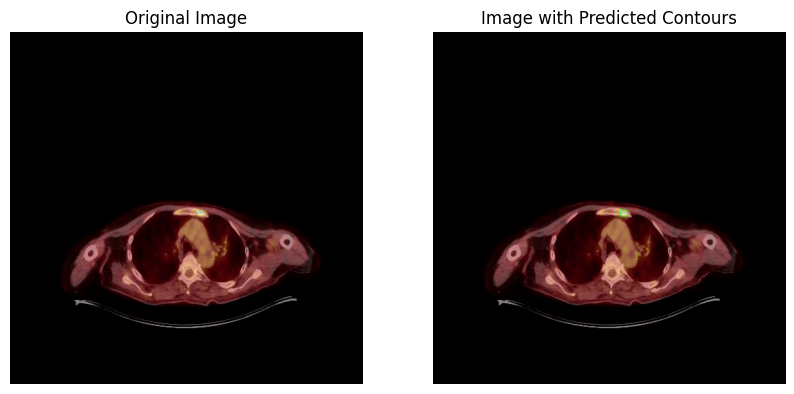

In [ ]:
def draw_predicted_contours(model, image_path, conf=CONF_THRESHOLD, colour=(0, 255, 0)):
    """Bir kesitin tahmin konturlarını çizer; (orijinal, konturlu) döndürür."""
    image = cv2.imread(image_path)
    canvas = image.copy()

    for mask in predicted_masks(model, image, conf=conf):
        binary = (mask > 0.5).astype(np.uint8) * 255
        contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(canvas, contours, -1, colour, 2)

    return image, canvas


sample_name = sorted(f for f in os.listdir(IMAGES_VAL) if f.endswith(".png"))[0]
sample_path = os.path.join(IMAGES_VAL, sample_name)

original, with_contours = draw_predicted_contours(model, sample_path)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title(f"Orijinal — {sample_name}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(with_contours, cv2.COLOR_BGR2RGB))
plt.title("Tahmin edilen konturlar")
plt.axis("off")

plt.tight_layout()
plt.show()


### 4.2 Tahmin ile gerçek maskenin karşılaştırılması

Üç panel: girdi kesiti, etiketten üretilen gerçek maske ve modelin tahmini.


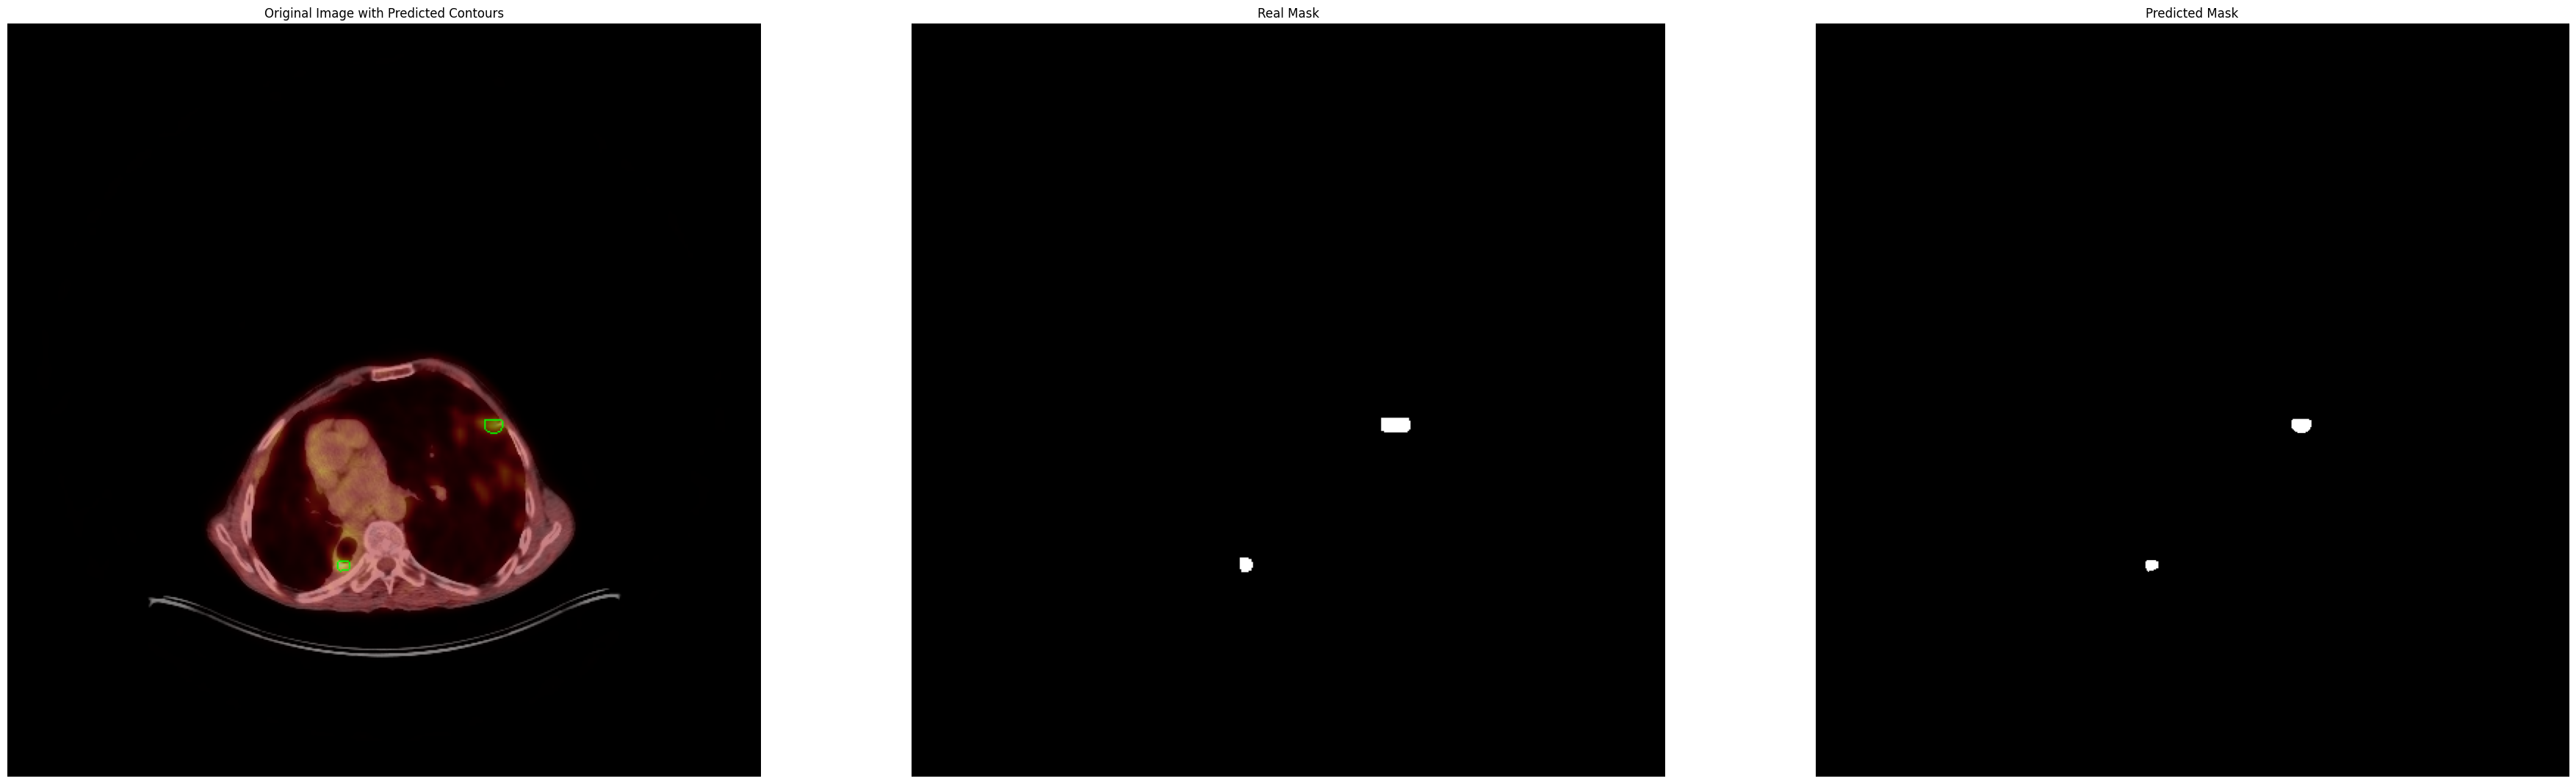

In [ ]:
real_masks = yolo_label_to_masks(
    os.path.join(LABELS_VAL, os.path.splitext(sample_name)[0] + ".txt"),
    (original.shape[1], original.shape[0]),
)
real_mask = combine_masks(real_masks, original.shape[:2])

preds = predicted_masks(model, original)
predicted_mask = combine_masks([(m > 0.5).astype(np.uint8) for m in preds],
                               original.shape[:2])

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title("Girdi kesiti")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(real_mask, cmap="gray")
plt.title("Gerçek maske (etiketten)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask, cmap="gray")
plt.title(f"Tahmin ({len(preds)} maske)")
plt.axis("off")

plt.tight_layout()
plt.show()


### 4.3 Gerçek maskenin doğrulanması

Eğitime giren etiketlerin gerçekten maske ürettiğini gözle kontrol etmek için
küçük bir denetim. Etiket dosyası bozuksa model değil **veri** sorunludur; bu
adım iki durumu ayırt etmeyi sağlar.


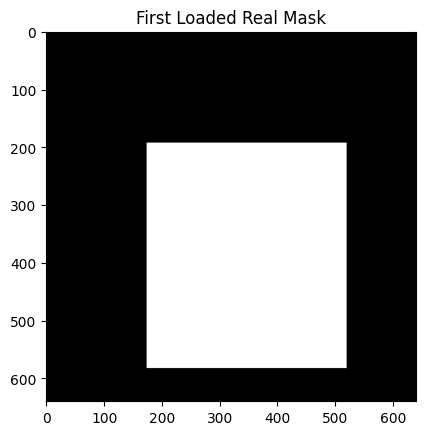

In [ ]:
plt.figure(figsize=(6, 6))
plt.imshow(real_mask, cmap="gray")
plt.title(f"Gerçek maske — {sample_name} ({len(real_masks)} lezyon)")
plt.axis("off")
plt.show()

print("Maskedeki lezyon piksel sayısı:", int(real_mask.sum()))


## 5. IoU ve eşleştirme

Kontur çizimi tek bir örnek gösterir. Modelin genel başarısını ölçmek için tahmin
maskeleri, etiketlerden üretilen gerçek maskelerle **IoU'ya göre** eşleştirilir.

* IoU ≥ 0,5 → **doğru pozitif (TP)**
* eşleşmeyen tahmin → **yanlış pozitif (FP)**
* eşleşmeyen gerçek maske → **yanlış negatif (FN)**


In [ ]:
def mask_iou(mask_a, mask_b):
    """İki ikili maske arasındaki IoU (Jaccard) skoru."""
    a = mask_a > 0.5
    b = mask_b > 0
    union = np.logical_or(a, b).sum()
    if union == 0:
        return 0.0
    return float(np.logical_and(a, b).sum() / union)


def match_masks(pred_masks, real_masks, iou_threshold=IOU_THRESHOLD):
    """Tahmin ve gerçek maskeleri IoU'ya göre eşleştirir (açgözlü algoritma).

    Her gerçek maske için en yüksek IoU'lu, henüz eşleşmemiş tahmin aranır.

    Returns:
        (eşleşmeler, eşleşmeyen tahmin sayısı, eşleşmeyen gerçek sayısı)
        Burada `eşleşmeler` = [(tahmin_indeksi, gerçek_indeksi, iou), ...]
    """
    iou_matrix = np.zeros((len(pred_masks), len(real_masks)))
    for p, pred in enumerate(pred_masks):
        for r, real in enumerate(real_masks):
            iou_matrix[p, r] = mask_iou(pred, real)

    matches, matched_pred, matched_real = [], set(), set()
    for r in range(len(real_masks)):
        for p in np.argsort(-iou_matrix[:, r]):
            if p in matched_pred:
                continue
            if iou_matrix[p, r] >= iou_threshold:
                matched_pred.add(int(p))
                matched_real.add(r)
                matches.append((int(p), r, float(iou_matrix[p, r])))
            break

    return matches, len(pred_masks) - len(matched_pred), len(real_masks) - len(matched_real)


In [ ]:
matches, missed_pred, missed_real = match_masks(preds, real_masks)

print(f"Tahmin sayısı        : {len(preds)}")
print(f"Eşleşen (TP)         : {len(matches)}")
print(f"Eşleşmeyen tahmin (FP): {missed_pred}")
print(f"Eşleşmeyen gerçek (FN): {missed_real}")
for p, r, iou in matches:
    print(f"  tahmin #{p} ↔ gerçek #{r}  IoU = {iou:.4f}")


### 5.1 Tespit edilen ve gerçek konturların üst üste gösterimi

Yeşil: modelin bulduğu sınır. Kırmızı: etiketteki gerçek sınır. Başlıkta eşleşme
IoU'su görünür.


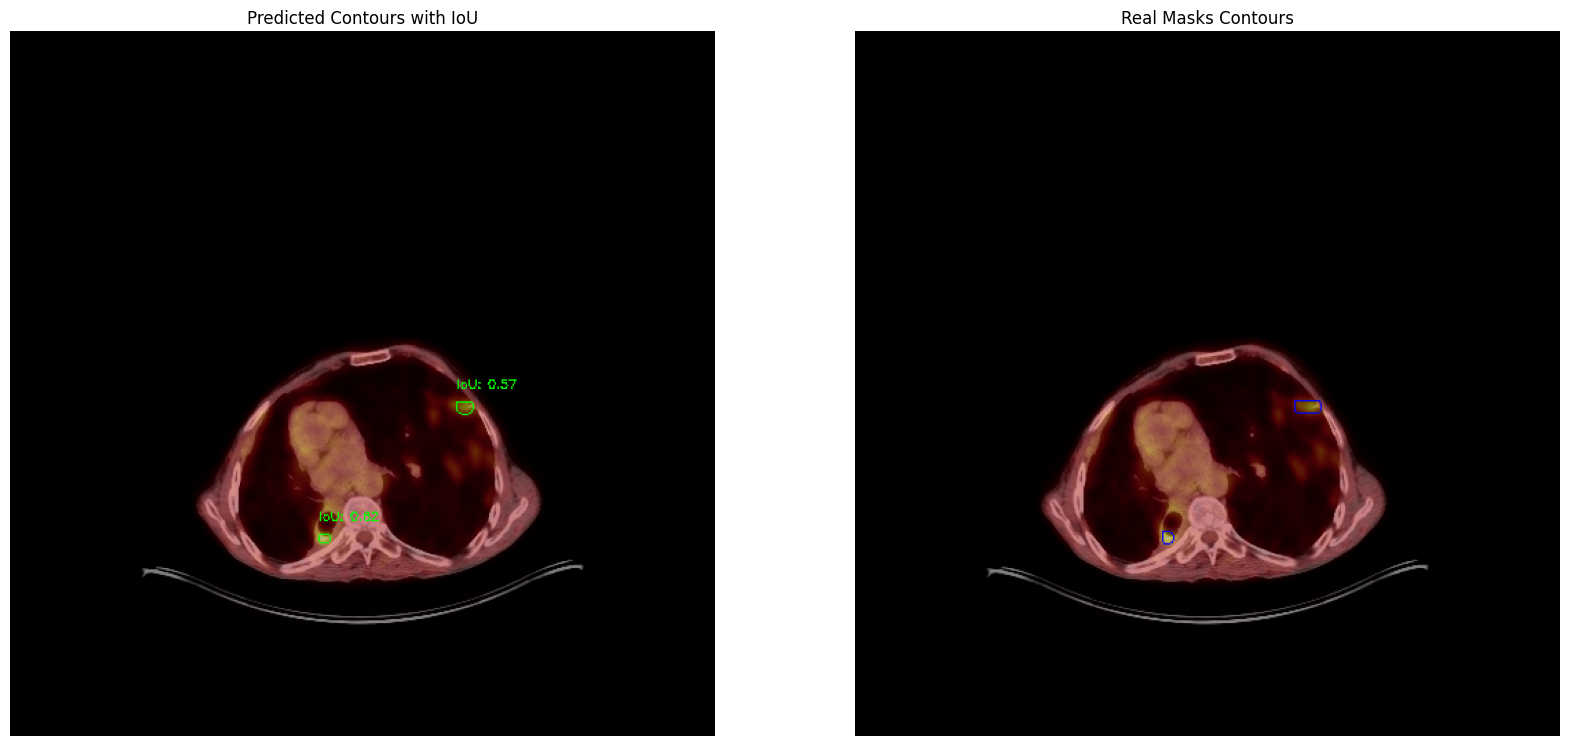

In [ ]:
img_with_predicted = original.copy()
img_with_real = original.copy()

for mask in preds:
    binary = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img_with_predicted, contours, -1, (0, 255, 0), 2)

if real_mask.sum() > 0:
    contours, _ = cv2.findContours(real_mask.astype(np.uint8) * 255,
                                   cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img_with_real, contours, -1, (255, 0, 0), 2)

best_iou = max((iou for _, _, iou in matches), default=0.0)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_with_predicted, cv2.COLOR_BGR2RGB))
plt.title(f"Tahmin edilen konturlar (en iyi IoU = {best_iou:.3f})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_with_real, cv2.COLOR_BGR2RGB))
plt.title("Gerçek konturlar")
plt.axis("off")

plt.tight_layout()
plt.show()


## 6. Veri kümesi düzeyinde değerlendirme

Tek bir kesit yanıltıcıdır. Aşağıdaki hücre, doğrulama kümesinin **tamamını**
tarar ve tespit düzeyinde kesinlik, duyarlılık, F1 ve IoU hesaplar.


In [ ]:
dataset_metrics = evaluate_dataset(model, IMAGES_VAL, LABELS_VAL)


### 6.1 Karışıklık matrisi (tespit düzeyinde)

Tek sınıflı tespitte klasik 2×2 karışıklık matrisi tam tanımlı değildir: "gerçek
negatif" (doğru şekilde lezyon bulunmadığını söylemek) tespit görevinde ayrı bir
sayım gerektirir. Bu nedenle matris, TP/FP/FN üçlüsünü gösterecek biçimde
çizilir.


In [ ]:
conf_matrix = np.array([
    [dataset_metrics["tp"], dataset_metrics["fn"]],
    [dataset_metrics["fp"], 0],
])

plt.figure(figsize=(5, 4))
plt.imshow(conf_matrix, cmap="Blues")
for (i, j), value in np.ndenumerate(conf_matrix):
    plt.text(j, i, str(value), ha="center", va="center",
             color="white" if value > conf_matrix.max() / 2 else "black", fontsize=14)

plt.xticks([0, 1], ["Tahmin: lezyon", "Tahmin: yok"])
plt.yticks([0, 1], ["Gerçek: lezyon", "Gerçek: yok"])
plt.title("Tespit Karışıklık Matrisi")
plt.tight_layout()
plt.show()


## Sonuçlar ve çıkarımlar

* **Model boyutu tek başına belirleyici değildir.** `yolov8n` yalnızca 10 epoch
  eğitildiği için en düşük IoU'yu vermiştir; aynı model 50 epoch'ta
  (`yolov8n_50epoch`) belirgin şekilde daha iyi sonuç alır. Bu, karşılaştırmanın
  model boyutundan çok **eğitim süresiyle** karıştığını gösterir.
* `yolov8m` (medium) en iyi dengeyi sağlar: `l` ve `x` varyantlarının sağladığı
  ek doğruluk, artan çıkarım süresini karşılamaz. Masaüstü arayüzünde
  `yolov8m-seg` kullanılmasının nedeni budur.
* En büyük model (`yolov8x`) bu veri kümesinde daha iyi değildir; küçük veri
  kümelerinde aşırı parametreleşme (over-parameterisation) doğruluğu artırmaz.
* Eğitim eğrileri ve epoch bazlı metrikler için her denemenin
  `runs/segment/<ad>/results.csv` dosyasına bakın.

### Değerlendirme yöntemi hakkında

Bu notebook'lardaki IoU değerleri, **tespit düzeyinde** hesaplanır: bir tahmin,
gerçek bir lezyonla IoU ≥ 0,5 ile eşleşirse doğru pozitif sayılır. Piksel düzeyinde
maske IoU'su ile karıştırılmamalıdır; maske kalitesi için
`results.csv` içindeki `metrics/mAP50(M)` ve `metrics/mAP50-95(M)` sütunları esastır.

> **Önceki sürümdeki eksik:** deney notebook'larında TP/FP/FN sayıları kod içine
> elle yazılmıştı (`TP = 433`, `FP = 82`, `FN = 80`). Bu yaklaşım, değerlerin hangi
> çalıştırmaya ait olduğunun izlenmesini imkânsız kılar ve hata yapmaya açıktır —
> `yolov8l` satırındaki tekrarlanan değerler bunun somut örneğidir. Bu sürümde
> metrikler veri üzerinden yeniden hesaplanır.
